Predicción y escenarios de riesgo de abstención. Semáforo territorial de riesgo de abstención electoral en México periodo 2009 - 2024

In [56]:
#PASO 1: Subir los archivos históricos 2009 - 2024 y unir todo en un dataframe

import pandas as pd
import os
import glob
import time

inicio = time.time()

patron_busqueda = r"C:\Users\icdm3\OneDrive\Documents\cursos\Hackaton INE\datos abiertos\*DatosAbiertos_DECEyEC*\*.csv"
archivos_csv = glob.glob(patron_busqueda)

print(f"Se encontraron {len(archivos_csv)} archivos para procesar.\n")

lista_tablas_nacional = []

for i, ruta_archivo in enumerate(archivos_csv):
    # Extraer el año del nombre de la carpeta
    nombre_carpeta = os.path.basename(os.path.dirname(ruta_archivo)) 
    anio_corto = nombre_carpeta[:2]
    
    if anio_corto == '09': anio = 2009
    elif anio_corto == '12': anio = 2012
    elif anio_corto == '15': anio = 2015
    elif anio_corto == '18': anio = 2018
    elif anio_corto == '21': anio = 2021
    elif anio_corto == '24': anio = 2024
    else: anio = int(anio_corto)

    try:
        df_temp = pd.read_csv(ruta_archivo, encoding='latin-1')
        
        columnas_renombrar = {
            'ENTIDAD': 'EDOCVE', 'NOM_ENT': 'EDONOM',
            'MUNICIPIO': 'MPIOCVE', 'NOM_MUN': 'MPIONOM',
            'TIPO_SEC': 'TIPOSEC'
        }
        df_temp.rename(columns=columnas_renombrar, inplace=True)
        
        columnas_agrupar = ['EDOCVE', 'EDONOM', 'MPIOCVE', 'SECCION']
        columnas_agrupar = [col for col in columnas_agrupar if col in df_temp.columns]
        
        if 'EDONOM' not in df_temp.columns:
            df_temp['EDONOM'] = 'Desconocido'
            columnas_agrupar.insert(1, 'EDONOM')
            
        df_agrupado = df_temp.groupby(columnas_agrupar)[['LN', 'SV', 'NV', 'NS']].sum().reset_index()
        
        df_agrupado['ABSTENCION'] = df_agrupado['NV'] / df_agrupado['LN']
        
        df_agrupado['AELEC'] = anio
        
        lista_tablas_nacional.append(df_agrupado)
        
        if (i + 1) % 20 == 0:
            print(f"Procesados {i + 1} de {len(archivos_csv)} archivos...")
            
    except Exception as e:
        print(f"Error con el archivo {os.path.basename(ruta_archivo)} (Carpeta {anio_corto}): {e}")

print("\nUniendo datos de todo el país...")

if len(lista_tablas_nacional) > 0:
    # Unir todo
    df_nacional = pd.concat(lista_tablas_nacional, ignore_index=True)
    
    df_nacional['EDOCVE'] = df_nacional['EDOCVE'].astype('category')
    df_nacional['EDONOM'] = df_nacional['EDONOM'].astype('category')
    df_nacional['AELEC'] = df_nacional['AELEC'].astype('int32')

    print(f"\n ¡Base histórica NACIONAL creada con éxito!")
    print(f"Total de registros (secciones-año): {len(df_nacional)}")
    print(f"Tiempo de ejecución: {round(time.time() - inicio, 2)} segundos.")

    display(df_nacional.head())
else:
    print("\n No se pudo procesar ningún archivo. Revisa los errores.")

Se encontraron 192 archivos para procesar.



C:\Users\icdm3\AppData\Local\Temp\ipykernel_24432\1418830786.py:31: DtypeWarning: Columns (8: DEF, 9: DEL) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(ruta_archivo, encoding='latin-1')
C:\Users\icdm3\AppData\Local\Temp\ipykernel_24432\1418830786.py:38: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_temp.rename(columns=columnas_renombrar, inplace=True)


Procesados 20 de 192 archivos...
Procesados 40 de 192 archivos...
Procesados 60 de 192 archivos...
Procesados 80 de 192 archivos...
Procesados 100 de 192 archivos...
Procesados 120 de 192 archivos...
Procesados 140 de 192 archivos...
Procesados 160 de 192 archivos...
Procesados 180 de 192 archivos...

Uniendo datos de todo el país...

 ¡Base histórica NACIONAL creada con éxito!
Total de registros (secciones-año): 406866
Tiempo de ejecución: 67.12 segundos.


,EDOCVE,EDONOM,MPIOCVE,SECCION,LN,SV,NV,NS,ABSTENCION,AELEC
0,1,AGUASCALIENTES,1,1,1880,1002,878,0,0.467021,2009
1,1,AGUASCALIENTES,1,2,957,441,516,0,0.539185,2009
2,1,AGUASCALIENTES,1,3,1541,718,823,0,0.534069,2009
3,1,AGUASCALIENTES,1,4,1280,638,642,0,0.501563,2009
4,1,AGUASCALIENTES,1,5,871,439,432,0,0.495982,2009


In [ ]:
# PASO 2: Calcular la tendencia histórica por sección

import numpy as np

conteo_anios = df_nacional.groupby(['EDOCVE', 'MPIOCVE', 'SECCION'])['AELEC'].nunique()
secciones_validas = conteo_anios[conteo_anios >= 4].index

df_riesgo = df_nacional.set_index(['EDOCVE', 'MPIOCVE', 'SECCION']).loc[secciones_validas].reset_index()

# Cálculo de la pendiente de tendencia (regresión lineal simple con Numpy)
def calcular_tendencia(group):
    if len(group) < 2:
        return 0
    # x = años, y = abstención
    x = group['AELEC'].values
    y = group['ABSTENCION'].values
    # polyfit devuelve la pendiente (slope) y el intercepto
    slope, _ = np.polyfit(x, y, 1)
    return slope

# Agrupar por sección y calcular métricas
df_perfil = df_riesgo.groupby(['EDOCVE', 'EDONOM', 'MPIOCVE', 'SECCION']).agg(
    ABSTENCION_PROMEDIO=('ABSTENCION', 'mean'),
    ABSTENCION_ULTIMO=('ABSTENCION', 'last'), # Último año registrado
    VOLATILIDAD=('ABSTENCION', 'std'),        # Desviación estándar
    ELECCIONES_REGISTRADAS=('AELEC', 'count')
).reset_index()

# Calcular la tendencia para cada sección (usando apply, puede tardar unos segundos)
tendencias = df_riesgo.groupby(['EDOCVE', 'MPIOCVE', 'SECCION']).apply(calcular_tendencia).reset_index(name='TENDENCIA')

# Unir todo en un solo DataFrame
df_perfil = pd.merge(df_perfil, tendencias, on=['EDOCVE', 'MPIOCVE', 'SECCION'], how='left')

# Calcular el promedio de abstención de los últimos 3 procesos para cada sección
def promedio_ultimos_3(group):
    # Ordenamos por año y tomamos los últimos 3
    ultimos_3 = group.sort_values('AELEC').tail(3)
    return ultimos_3['ABSTENCION'].mean()

prom_3 = df_riesgo.groupby(['EDOCVE', 'MPIOCVE', 'SECCION']).apply(promedio_ultimos_3).reset_index(name='ABSTENCION_ULTIMOS_3')

df_perfil = pd.merge(df_perfil, prom_3, on=['EDOCVE', 'MPIOCVE', 'SECCION'], how='left')

print(f"Perfil de riesgo creado para {len(df_perfil)} secciones en todo el país.")
display(df_perfil.head())

Perfil de riesgo creado para 73836 secciones en todo el país.


,EDOCVE,EDONOM,MPIOCVE,SECCION,ABSTENCION_PROMEDIO,ABSTENCION_ULTIMO,VOLATILIDAD,ELECCIONES_REGISTRADAS,TENDENCIA,ABSTENCION_ULTIMOS_3
0,1,AGUASCALIENTES,1,1,0.302132,0.204195,0.127821,6,-0.017081,0.204840
1,1,AGUASCALIENTES,1,2,0.474157,0.415767,0.085912,6,-0.004711,0.445638
2,1,AGUASCALIENTES,1,3,0.395774,0.281143,0.126241,6,-0.010268,0.336069
3,1,AGUASCALIENTES,1,4,0.403684,0.288778,0.127361,6,-0.008733,0.345929
4,1,AGUASCALIENTES,1,5,0.388443,0.340909,0.115186,6,-0.007101,0.334291


In [ ]:
#PASO 3: Cruce entre datos de abstención y el censo de población 2020 del INE

import pandas as pd

ruta_censo = r"C:\Users\icdm3\OneDrive\Documents\cursos\Hackaton INE\datos abiertos\INE_SECCION_2020.csv"

try:
    df_censo = pd.read_csv(ruta_censo, encoding='latin-1', sep=None, engine='python')
    print(" Archivo del Censo 2020 cargado correctamente.")
except Exception as e:
    print(f" Error al cargar: {e}")
    print("Intentaremos asumiendo que está separado por comas...")
    df_censo = pd.read_csv(ruta_censo, encoding='latin-1')

if 'ENTIDAD' in df_censo.columns:
    df_censo.rename(columns={'ENTIDAD': 'EDOCVE'}, inplace=True)

columnas_deseadas = [
    'EDOCVE', 'SECCION', 'TIPO', 'POBTOT', 
    'P_18A24', 'P_60YMAS', 'POBFEM', 
    'GRAPROES', 'P15YM_AN', 'VPH_S_ELEC', 'VPH_NODREN', 'PDESOCUP'
]

columnas_disponibles = [col for col in columnas_deseadas if col in df_censo.columns]
df_censo_sub = df_censo[columnas_disponibles].copy()

df_final = pd.merge(df_perfil, df_censo_sub, on=['EDOCVE', 'SECCION'], how='inner')

print(f"Secciones cruzadas exitosamente: {len(df_final)}")

df_final['PORC_JOVENES'] = df_final['P_18A24'] / df_final['POBTOT'].replace(0, pd.NA)
df_final['PORC_ADULTOS_MAYORES'] = df_final['P_60YMAS'] / df_final['POBTOT'].replace(0, pd.NA)
df_final['PORC_MUJERES'] = df_final['POBFEM'] / df_final['POBTOT'].replace(0, pd.NA)
df_final['PORC_ANALFABETAS'] = df_final['P15YM_AN'] / df_final['POBTOT'].replace(0, pd.NA)
df_final['PORC_SIN_DRENAJE'] = df_final['VPH_NODREN'] / df_final['POBTOT'].replace(0, pd.NA) 

perfil_por_riesgo = df_final.groupby('NIVEL_RIESGO')[[
    'PORC_JOVENES', 'PORC_ADULTOS_MAYORES', 'PORC_MUJERES', 
    'GRAPROES', 'PORC_ANALFABETAS', 'PORC_SIN_DRENAJE'
]].mean().round(4)

print("\n--- PERFIL SOCIODEMOGRÁFICO PROMEDIO POR NIVEL DE RIESGO ---")
display(perfil_por_riesgo)

# la distribución del tipo de sección (Urbana/Rural)
if 'TIPO' in df_final.columns:
    print("\n--- TIPO DE SECCIÓN POR NIVEL DE RIESGO (Porcentaje) ---")
    tipo_por_riesgo = pd.crosstab(df_final['NIVEL_RIESGO'], df_final['TIPO'], normalize='index') * 100
    display(tipo_por_riesgo.round(2))

✅ Archivo del Censo 2020 cargado correctamente.
Secciones cruzadas exitosamente: 73114

--- PERFIL SOCIODEMOGRÁFICO PROMEDIO POR NIVEL DE RIESGO ---


C:\Users\icdm3\AppData\Local\Temp\ipykernel_24432\13427598.py:14: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_censo.rename(columns={'ENTIDAD': 'EDOCVE'}, inplace=True)


,PORC_JOVENES,PORC_ADULTOS_MAYORES,PORC_MUJERES,GRAPROES,PORC_ANALFABETAS,PORC_SIN_DRENAJE
NIVEL_RIESGO,,,,,,
ALTO,0.11725,0.117549,0.499584,7.8827,0.05029,0.022943
BAJO,0.109476,0.15901,0.514523,9.6946,0.037541,0.014897
MEDIO,0.11869,0.123847,0.50311,8.5542,0.040675,0.017195



--- TIPO DE SECCIÓN POR NIVEL DE RIESGO (Porcentaje) ---


TIPO,2,3,4
NIVEL_RIESGO,,,
ALTO,47.13,13.43,39.44
BAJO,67.25,8.37,24.38
MEDIO,62.37,9.55,28.08


In [ ]:
columnas_entrega = [
    'EDOCVE', 'EDONOM', 'MPIOCVE', 'SECCION', 'NIVEL_RIESGO',
    'ABSTENCION_PROMEDIO', 'ABSTENCION_ULTIMO', 'ABSTENCION_ULTIMOS_3',
    'TENDENCIA', 'VOLATILIDAD',
    'PORC_JOVENES', 'PORC_ADULTOS_MAYORES', 'PORC_MUJERES', 
    'GRAPROES', 'PORC_ANALFABETAS', 'PORC_SIN_DRENAJE'
]

# Verificamos qué columnas existen en el DataFrame final y las exportamos
df_entrega = df_final[[col for col in columnas_entrega if col in df_final.columns]]

# Guardamos el CSV
nombre_csv = "Semaforo_Riesgo_Abstencion_INEE_2024.csv"
df_entrega.to_csv(nombre_csv, index=False, encoding='utf-8-sig')
print(f" Base de datos anonimizada exportada como: {nombre_csv}")

# Calcular el Top 10 de Estados con más secciones en Riesgo ALTO
top_estados_riesgo = df_entrega[df_entrega['NIVEL_RIESGO'] == 'ALTO']['EDONOM'].value_counts().head(10)
print("\n--- TOP 10 ESTADOS CON MÁS SECCIONES EN RIESGO ALTO ---")
print(top_estados_riesgo)

resumen_estados = df_entrega.groupby('EDONOM')['NIVEL_RIESGO'].value_counts(normalize=True).unstack().fillna(0) * 100
resumen_estados.to_csv("Resumen_Riesgo_por_Estado.csv", encoding='utf-8-sig')
print("\n Resumen por estado exportado.")

✅ Base de datos anonimizada exportada como: Semaforo_Riesgo_Abstencion_INEE_2024.csv

--- TOP 10 ESTADOS CON MÁS SECCIONES EN RIESGO ALTO ---
EDONOM
GUANAJUATO         474
SONORA             274
NUEVO LEON         238
JALISCO            176
BAJA CALIFORNIA    135
DURANGO            122
MICHOACAN          106
OAXACA              96
SINALOA             68
CHIHUAHUA           66
Name: count, dtype: int64

✅ Resumen por estado exportado.


In [45]:
# Crear una tabla formateada para el documento
top_estados_ordenados = top_estados_riesgo.reset_index()
top_estados_ordenados.columns = ['Entidad Federativa', 'Secciones en Riesgo Alto']

# Poner los nombres en formato Título (Ej. Guanajuato en vez de GUANAJUATO)
top_estados_ordenados['Entidad Federativa'] = top_estados_ordenados['Entidad Federativa'].str.title()

# Agregar una columna de "Lugar" (del 1 al 10)
top_estados_ordenados.insert(0, 'Lugar', range(1, 11))

# Exportar esta tabla lista para copiar a Word
top_estados_ordenados.to_csv("Tabla_Top10_Estados.csv", index=False)
print("\n¡Tabla formateada exportada como 'Tabla_Top10_Estados.csv'!")


¡Tabla formateada exportada como 'Tabla_Top10_Estados.csv'!


In [ ]:
#PASO 4: Generar el mapa de semáforo
import geopandas as gpd
import pandas as pd
import time

inicio = time.time()
print("Cargando shapefile del INE...")

ruta_shapefile = r"C:\Users\icdm3\OneDrive\Documents\cursos\Hackaton INE\datos abiertos\shapefile\SECCION.shp"

mapa_ine = gpd.read_file(ruta_shapefile)
print(f"Shapefile cargado con {len(mapa_ine)} polígonos.")

print("Columnas en el shapefile:", mapa_ine.columns.tolist())

col_entidad_shp = 'ENTIDAD' if 'ENTIDAD' in mapa_ine.columns else 'EDOCVE'
col_seccion_shp = 'SECCION' if 'SECCION' in mapa_ine.columns else 'SECCION_EL'

mapa_ine[col_seccion_shp] = mapa_ine[col_seccion_shp].astype(int)
mapa_ine[col_entidad_shp] = mapa_ine[col_entidad_shp].astype(int)

df_entrega['SECCION'] = df_entrega['SECCION'].astype(int)
df_entrega['EDOCVE'] = df_entrega['EDOCVE'].astype(int)

mapa_riesgo = mapa_ine.merge(
    df_entrega, 
    left_on=[col_entidad_shp, col_seccion_shp], 
    right_on=['EDOCVE', 'SECCION'], 
    how='left'
)

mapa_riesgo['NIVEL_RIESGO'] = mapa_riesgo['NIVEL_RIESGO'].fillna('SIN DATOS')

# Exportar el resultado como GeoJSON y GPKG
print("Exportando mapa a GeoJSON y GPKG...")
mapa_riesgo.to_file("Mapa_Riesgo_INEE.geojson", driver="GeoJSON")
mapa_riesgo.to_file("Mapa_Riesgo_INEE.gpkg", driver="GPKG")

print(f"\n ¡Mapa generado con éxito en {round(time.time() - inicio, 2)} segundos!")
print("Archivos listos en tu carpeta del proyecto: Mapa_Riesgo_INEE.geojson y Mapa_Riesgo_INEE.gpkg")

Cargando shapefile del INE...
Shapefile cargado con 71541 polígonos.
Columnas en el shapefile: ['ID', 'ENTIDAD', 'DISTRITO_F', 'DISTRITO_L', 'MUNICIPIO', 'SECCION', 'TIPO', 'CONTROL', 'GEOMETRY1_', 'geometry']
Exportando mapa a GeoJSON y GPKG...

 ¡Mapa generado con éxito en 23.37 segundos!
Archivos listos en tu carpeta del proyecto: Mapa_Riesgo_INEE.geojson y Mapa_Riesgo_INEE.gpkg


Dibujando el mapa nacional...


C:\Users\icdm3\AppData\Local\Temp\ipykernel_24432\1027454958.py:14: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  mapa_riesgo.plot(


¡Mapa guardado exitosamente como 'Mapa1_Seccional_Nacional.png'!


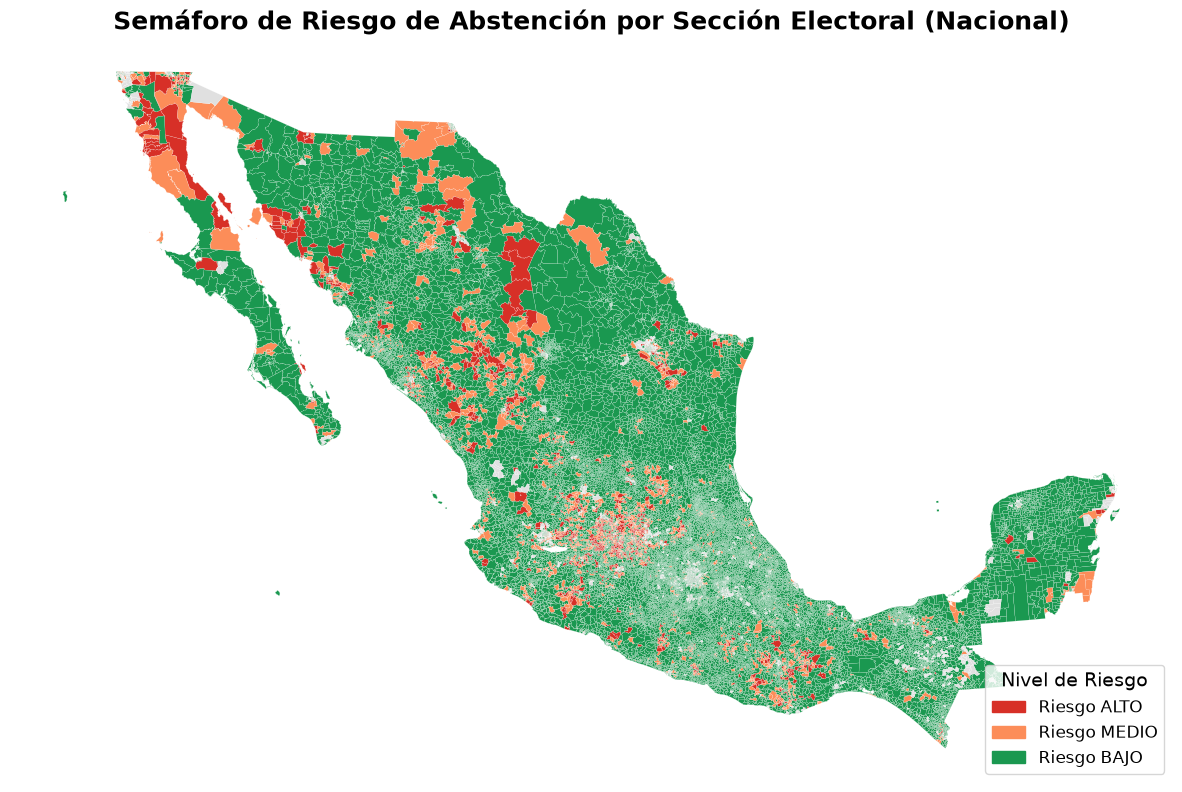

In [57]:
import matplotlib.pyplot as plt

colores = {
    'ALTO': '#d73027',   # Rojo
    'MEDIO': '#fc8d59',  # Naranja
    'BAJO': '#1a9850',   # Verde
    'SIN DATOS': '#e0e0e0' # Gris claro
}

print("Dibujando el mapa nacional...")

fig, ax = plt.subplots(1, 1, figsize=(15, 12))

mapa_riesgo.plot(
    column='NIVEL_RIESGO',
    ax=ax,
    color=mapa_riesgo['NIVEL_RIESGO'].map(colores),
    linewidth=0.1, # Líneas delgadas para que se vea bien a nivel nacional
    edgecolor='white'
)

ax.set_title('Semáforo de Riesgo de Abstención por Sección Electoral (Nacional)', fontsize=18, fontweight='bold')
ax.axis('off') # Ocultamos los ejes X e Y

import matplotlib.patches as mpatches
leyenda = [
    mpatches.Patch(color='#d73027', label='Riesgo ALTO'),
    mpatches.Patch(color='#fc8d59', label='Riesgo MEDIO'),
    mpatches.Patch(color='#1a9850', label='Riesgo BAJO')
]
ax.legend(handles=leyenda, loc='lower right', title="Nivel de Riesgo", fontsize=12, title_fontsize=14)

plt.savefig("Mapa1_Seccional_Nacional.png", dpi=300, bbox_inches='tight', facecolor='white')
print("¡Mapa guardado exitosamente como 'Mapa1_Seccional_Nacional.png'!")

plt.show()

In [ ]:
# PASO 5: SIMULACIÓN DE ESCENARIOS DE RIESGO
print("\n--- SIMULANDO ESCENARIOS ---")

# 1. Escenario Base (Sin intervención)
df_pivot['Prob_Sin_Intervencion'] = df_pivot['Probabilidad_Alto_Riesgo']
df_pivot['Semaforo_Sin_Intervencion'] = df_pivot['Prob_Sin_Intervencion'].apply(asignar_semaforo)

# 2. Escenario con Intervención Hipotética
X_intervencion = X.copy()
X_intervencion['% Participación'] = X_intervencion['% Participación'] * 1.10 
X_intervencion['% Votos no esp.'] = X_intervencion['% Votos no esp.'] * 0.95

# Aseguramos que la participación no pase del 100%
X_intervencion['% Participación'] = np.where(X_intervencion['% Participación'] > 1.0, 1.0, X_intervencion['% Participación'])

# Escalamos los nuevos datos y predecimos
X_intervencion_scaled = scaler.transform(X_intervencion)
df_pivot['Prob_Con_Intervencion'] = modelo.predict_proba(X_intervencion_scaled)[:, 1]
df_pivot['Semaforo_Con_Intervencion'] = df_pivot['Prob_Con_Intervencion'].apply(asignar_semaforo)

# 3. Crear tabla comparativa
comparacion = df_pivot[['Nombre', 'Prob_Sin_Intervencion', 'Semaforo_Sin_Intervencion', 'Prob_Con_Intervencion', 'Semaforo_Con_Intervencion']].copy()
comparacion = comparacion.sort_values(by='Prob_Sin_Intervencion', ascending=False)

# Imprimir comparación de los estados con más riesgo
print("\n--- COMPARACIÓN DE ESCENARIOS (Top 10 Estados con mayor riesgo sin intervención) ---")
print(comparacion.head(10).to_string(index=False))

comparacion.to_csv("escenarios_comparados.csv", index=False)
print("\n Archivo 'escenarios_comparados.csv' guardado.")


--- SIMULANDO ESCENARIOS ---

--- COMPARACIÓN DE ESCENARIOS (Top 10 Estados con mayor riesgo sin intervención) ---
             Nombre  Prob_Sin_Intervencion Semaforo_Sin_Intervencion  Prob_Con_Intervencion Semaforo_Con_Intervencion
    Baja California               0.993744                    🔴 Alto               0.951840                    🔴 Alto
             Sonora               0.976594                    🔴 Alto               0.823358                    🔴 Alto
          Chihuahua               0.934403                    🔴 Alto               0.591608                   🟡 Medio
Baja California Sur               0.898913                    🔴 Alto               0.457378                   🟡 Medio
            Durango               0.886469                    🔴 Alto               0.416923                   🟡 Medio
          Michoacán               0.882790                    🔴 Alto               0.408308                   🟡 Medio
       Quintana Roo               0.829494                


¡Éxito! La tabla se ha guardado como imagen en: Tabla_Escenarios.png


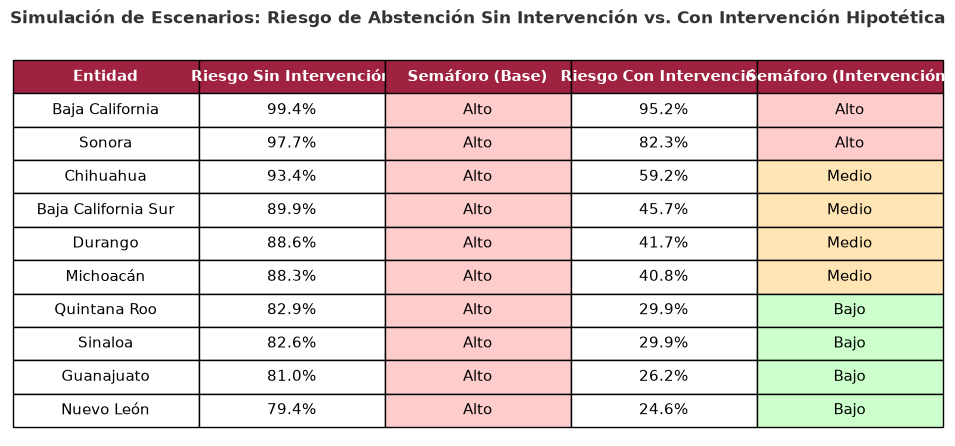

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df_comp = pd.read_csv("escenarios_comparados.csv")

top_10 = df_comp.head(10).copy()

top_10['Prob_Sin_Intervencion'] = (top_10['Prob_Sin_Intervencion'] * 100).round(1).astype(str) + '%'
top_10['Prob_Con_Intervencion'] = (top_10['Prob_Con_Intervencion'] * 100).round(1).astype(str) + '%'

top_10['Semaforo_Sin_Intervencion'] = top_10['Semaforo_Sin_Intervencion'].str.replace('🔴 ', '').str.replace('🟡 ', '').str.replace('🟢 ', '')
top_10['Semaforo_Con_Intervencion'] = top_10['Semaforo_Con_Intervencion'].str.replace('🔴 ', '').str.replace('🟡 ', '').str.replace('🟢 ', '')

top_10.columns = ['Entidad', 'Riesgo Sin Intervención', 'Semáforo (Base)', 'Riesgo Con Intervención', 'Semáforo (Intervención)']

fig, ax = plt.subplots(figsize=(10, 5)) # Tamaño de la imagen
ax.axis('off') # Ocultamos los ejes

# Crear la tabla
tabla = ax.table(
    cellText=top_10.values,
    colLabels=top_10.columns,
    cellLoc='center',
    loc='center'
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1.2, 2) # Ancho y alto de las celdas

for (row, col), cell in tabla.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#9F2241') # Color guinda oficial
    else:
        if col == 2: # Columna Semáforo Base
            if top_10.iloc[row-1, 2] == 'Alto': cell.set_facecolor('#ffcccc')
            elif top_10.iloc[row-1, 2] == 'Medio': cell.set_facecolor('#ffe5b4')
            else: cell.set_facecolor('#ccffcc')
        if col == 4: # Columna Semáforo Intervención
            if top_10.iloc[row-1, 4] == 'Alto': cell.set_facecolor('#ffcccc')
            elif top_10.iloc[row-1, 4] == 'Medio': cell.set_facecolor('#ffe5b4')
            else: cell.set_facecolor('#ccffcc')

plt.title('Simulación de Escenarios: Riesgo de Abstención Sin Intervención vs. Con Intervención Hipotética', 
          fontsize=12, fontweight='bold', pad=20, color='#333333')

nombre_imagen = "Tabla_Escenarios.png"
plt.savefig(nombre_imagen, dpi=300, bbox_inches='tight', facecolor='white')
print(f"\n¡Éxito! La tabla se ha guardado como imagen en: {nombre_imagen}")

plt.show()

1. Cargando la tabla general estatal...
2. Entrenando el modelo...

--- Precisión (Accuracy): 100.00% ---

3. Generando la imagen de la tabla...
¡Éxito! La tabla se ha guardado como imagen en: Tabla_Semaforo_Estados.png


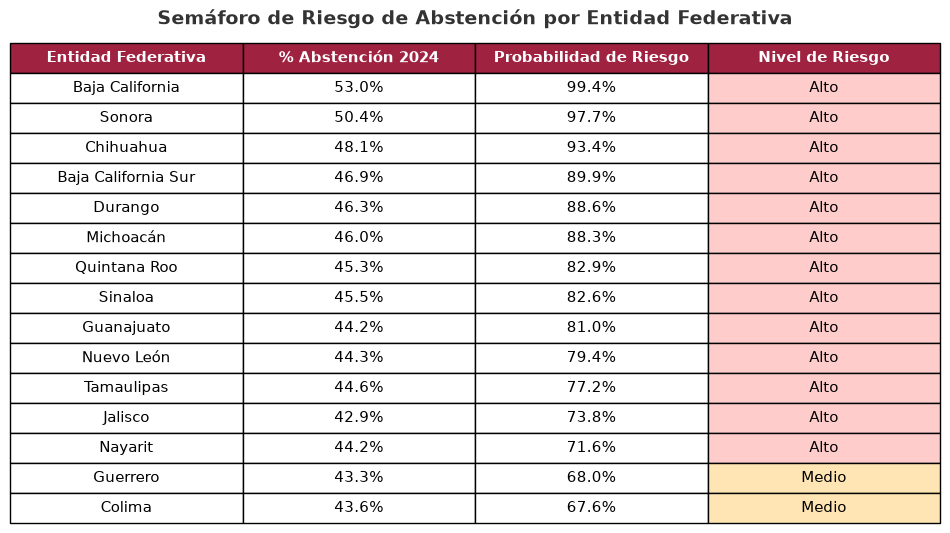

In [ ]:
#PASO 6: Modelo de Regresión Logística 
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

ruta_general = r"C:\Users\icdm3\OneDrive\Documents\cursos\Hackaton INE\datos abiertos\Tabla General_data.csv"

print("1. Cargando la tabla general estatal...")

df = pd.read_csv(ruta_general, sep=None, engine='python', encoding='utf-8-sig')

df.columns = ['Ent', 'Nombre', 'Medida', 'i', 'Orden', 'Valor']
df_pivot = df.pivot_table(
    index=['Ent', 'Nombre'], 
    columns='Medida', 
    values='Valor', 
    aggfunc='first'
).reset_index()
df_pivot.columns.name = None
df_pivot.columns = df_pivot.columns.str.strip()

cols_numericas = ['% Abstención', '% Participación', 'Lista nominal', 'Sí votaron', 'No votaron']
for col in cols_numericas:
    if col in df_pivot.columns:
        df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

# CREAR VARIABLE DEPENDIENTE (Y)
umbral_abstencion = 0.415
df_pivot['Alto_Riesgo'] = (df_pivot['% Abstención'] > umbral_abstencion).astype(int)

# CREAR VARIABLES INDEPENDIENTES (X)
X = df_pivot[['% Participación', '% Votos no esp.', 'Lista nominal']].copy()
X = X.fillna(X.mean())
y = df_pivot['Alto_Riesgo']

# ENTRENAR LA REGRESIÓN LOGÍSTICA
print("2. Entrenando el modelo...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
modelo = LogisticRegression(class_weight='balanced', random_state=42)
modelo.fit(X_scaled, y)

# PREDECIR PROBABILIDADES Y EVALUAR
df_pivot['Probabilidad_Alto_Riesgo'] = modelo.predict_proba(X_scaled)[:, 1]
y_pred = modelo.predict(X_scaled)
precision = accuracy_score(y, y_pred)

print(f"\n--- Precisión (Accuracy): {precision * 100:.2f}% ---")

#  CREAR LA TABLA DEL SEMÁFORO
resultado = df_pivot[['Nombre', '% Abstención', 'Probabilidad_Alto_Riesgo']].sort_values(by='Probabilidad_Alto_Riesgo', ascending=False)

def asignar_semaforo(prob):
    if prob > 0.7: return 'Alto' # Quitamos los emojis para que matplotlib no falle
    elif prob > 0.4: return 'Medio'
    else: return 'Bajo'

resultado['Semáforo'] = resultado['Probabilidad_Alto_Riesgo'].apply(asignar_semaforo)

resultado.to_csv("semaforo_estados.csv", index=False)

print("\n3. Generando la imagen de la tabla...")

df_tabla = resultado.head(15).copy()
df_tabla['% Abstención'] = (df_tabla['% Abstención'] * 100).round(1).astype(str) + '%'
df_tabla['Probabilidad_Alto_Riesgo'] = (df_tabla['Probabilidad_Alto_Riesgo'] * 100).round(1).astype(str) + '%'

df_tabla.columns = ['Entidad Federativa', '% Abstención 2024', 'Probabilidad de Riesgo', 'Nivel de Riesgo']

fig, ax = plt.subplots(figsize=(10, 6)) 
ax.axis('off') # Ocultar ejes

# Crear la tabla
tabla = ax.table(
    cellText=df_tabla.values,
    colLabels=df_tabla.columns,
    cellLoc='center',
    loc='center'
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1.2, 1.8) # Ancho y alto de las celdas

for (row, col), cell in tabla.get_celld().items():
    if row == 0:
        
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#9F2241') 
    else:
        # Colorear la columna de Nivel de Riesgo (columna 3)
        if col == 3:
            if df_tabla.iloc[row-1, 3] == 'Alto': cell.set_facecolor('#ffcccc')
            elif df_tabla.iloc[row-1, 3] == 'Medio': cell.set_facecolor('#ffe5b4')
            else: cell.set_facecolor('#ccffcc')

plt.title('Semáforo de Riesgo de Abstención por Entidad Federativa', 
          fontsize=14, fontweight='bold', pad=20, color='#333333')

# Guardar la imagen 
nombre_imagen = "Tabla_Semaforo_Estados.png"
plt.savefig(nombre_imagen, dpi=300, bbox_inches='tight', facecolor='white')
print(f"¡Éxito! La tabla se ha guardado como imagen en: {nombre_imagen}")

plt.show()

In [58]:
import geopandas as gpd

ruta_shape = r"C:\Users\icdm3\OneDrive\Documents\cursos\Hackaton INE\datos abiertos\shapefile\MUNICIPIO.shp"
gdf = gpd.read_file(ruta_shape)

print("COLUMNAS DISPONIBLES EN EL SHAPEFILE")
print(gdf.columns.tolist())

print("\n--- PRIMERAS 3 FILAS ---")
print(gdf.head(3))

COLUMNAS DISPONIBLES EN EL SHAPEFILE
['ID', 'ENTIDAD', 'MUNICIPIO', 'NOMBRE', 'CONTROL', 'GEOMETRY1_', 'geometry']

--- PRIMERAS 3 FILAS ---
       ID  ENTIDAD  MUNICIPIO   NOMBRE  CONTROL GEOMETRY1_  \
0   673.0       31          1    ABALA      0.0       None   
1  1634.0       19          1  ABASOLO      0.0       None   
2   562.0       28          1  ABASOLO      0.0       None   

                                            geometry  
0  POLYGON ((1276145.87 1024811.637, 1276482.753 ...  
1  POLYGON ((159924.235 1550155.209, 160089.147 1...  
2  POLYGON ((381359.689 1330786.371, 381249.106 1...  


1. Cargando datos y shapefile...
2. Generando el mapa municipal...
¡Éxito! Mapa guardado como 'Mapa_Municipal_Riesgo.png'.


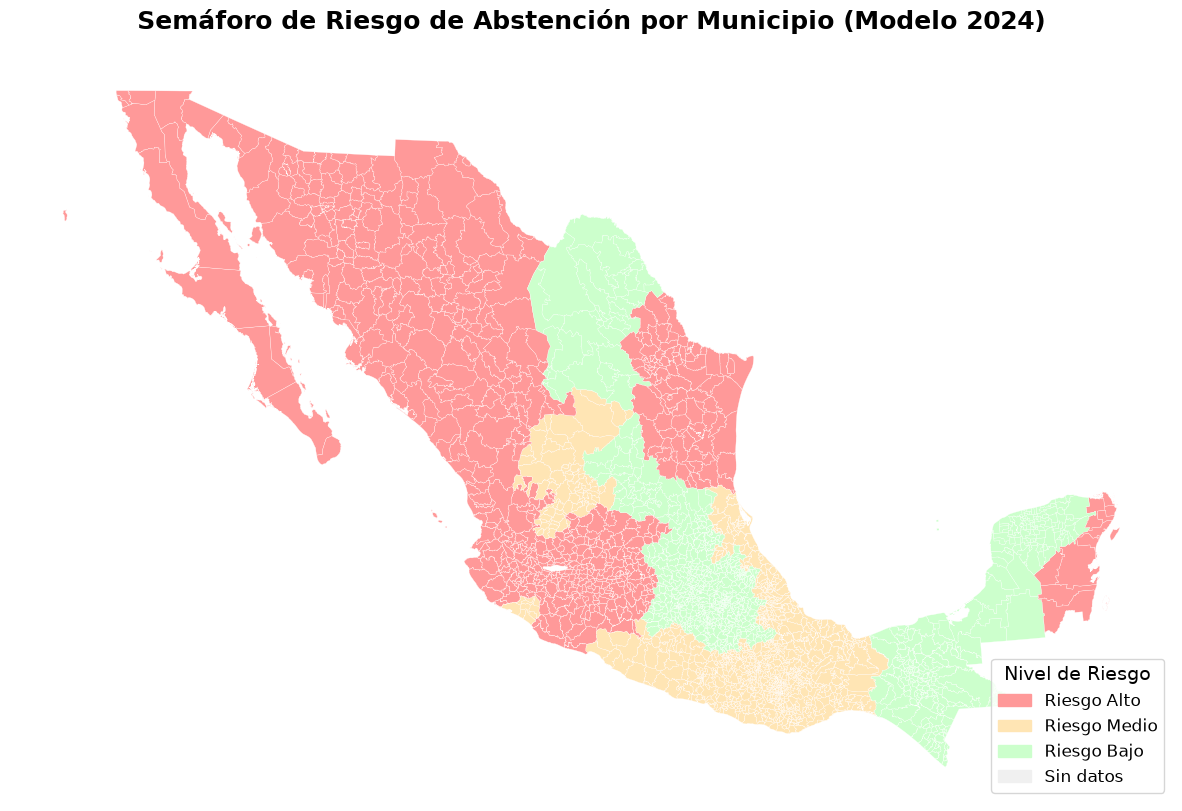

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

ruta_shape = r"C:\Users\icdm3\OneDrive\Documents\cursos\Hackaton INE\datos abiertos\shapefile\MUNICIPIO.shp"
ruta_resultados = "semaforo_estados.csv" 

print("1. Cargando datos y shapefile...")

# CARGAR RESULTADOS
df_res = pd.read_csv(ruta_resultados)

# Diccionario para traducir Nombres a los números del INEGI
mapa_entidades = {
    'Aguascalientes': 1, 'Baja California': 2, 'Baja California Sur': 3, 
    'Campeche': 4, 'Coahuila': 5, 'Colima': 6, 'Chiapas': 7, 
    'Chihuahua': 8, 'Ciudad de México': 9, 'Durango': 10, 
    'Guanajuato': 11, 'Guerrero': 12, 'Hidalgo': 13, 'Jalisco': 14, 
    'México': 15, 'Michoacán': 16, 'Morelos': 17, 'Nayarit': 18, 
    'Nuevo León': 19, 'Oaxaca': 20, 'Puebla': 21, 'Querétaro': 22, 
    'Quintana Roo': 23, 'San Luis Potosí': 24, 'Sinaloa': 25, 
    'Sonora': 26, 'Tabasco': 27, 'Tamaulipas': 28, 'Tlaxcala': 29, 
    'Veracruz': 30, 'Yucatán': 31, 'Zacatecas': 32
}

# Creamos la columna numérica en tus resultados
df_res['CVE_ENT'] = df_res['Nombre'].map(mapa_entidades)

# CARGAR SHAPEFILE
gdf_municipios = gpd.read_file(ruta_shape)

# UNIR 
gdf_mapa = gdf_municipios.merge(df_res, left_on='ENTIDAD', right_on='CVE_ENT', how='left')

# CONFIGURAR COLORES
colores = {
    'Bajo': '#ccffcc',  
    'Medio': '#ffe5b4',  
    'Alto': '#ff9999'    
}
gdf_mapa['color'] = gdf_mapa['Semáforo'].map(colores).fillna('#f0f0f0')

print("2. Generando el mapa municipal...")

# DIBUJAR EL MAPA
fig, ax = plt.subplots(1, 1, figsize=(15, 12))

gdf_mapa.plot(
    color=gdf_mapa['color'],
    linewidth=0.2, 
    ax=ax,
    edgecolor='white'
)

# ESTÉTICA
ax.set_title('Semáforo de Riesgo de Abstención por Municipio', fontsize=18, fontweight='bold', pad=20)
ax.axis('off')

# Leyenda
parches = [
    mpatches.Patch(color='#ff9999', label='Riesgo Alto'),
    mpatches.Patch(color='#ffe5b4', label='Riesgo Medio'),
    mpatches.Patch(color='#ccffcc', label='Riesgo Bajo'),
    mpatches.Patch(color='#f0f0f0', label='Sin datos')
]
ax.legend(handles=parches, title='Nivel de Riesgo', loc='lower right', fontsize=12, title_fontsize=14)

# GUARDAR
nombre_imagen = "Mapa_Municipal_Riesgo.png"
plt.savefig(nombre_imagen, dpi=300, bbox_inches='tight', facecolor='white')
print(f"¡Éxito! Mapa guardado como '{nombre_imagen}'.")

plt.show()